In [119]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils.prediction_utils as pred
from utils import dictionaries as dictionary
from utils.logger import setup_logger


In [120]:
# Fetch and preprocess data
def fetch_and_prep_data(query):
    try:
        df = query_to_df(query)
        df = prep_dataframe(df)
    except Exception as e:
        print(f"Error executing query: {str(e)}")
        return None
    return df

# Split data into train and test sets
def split_data(df, test_set_date):
    train_data = df[df['start_date'] < test_set_date]
    test_data = df[df['start_date'] >= test_set_date]
    return train_data, test_data

# Prepare features and target
def prepare_features_and_target(train_data, test_data, features, target):
    X_train = train_data[features]
    y_train = train_data[target]
    X_test = test_data[features]
    y_test = test_data[target]
    return X_train, y_train, X_test, y_test

def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'

def query_to_df(query):
    engine = create_sql_alchemy_engine()
    df_query = pd.read_sql_query(query, engine)

    return df_query

def create_sql_alchemy_engine():
    from sqlalchemy import create_engine
    from urllib.parse import quote_plus
    """
    Creates and returns a SQLAlchemy engine for connecting to a SQL Server database.
    """
    quoted = quote_plus(
        "Driver={ODBC+Driver+17+for+SQL+Server};"
        "Server=tcp:stercampsql.database.windows.net;"
        "Database=SterCampNew;"
        "uid=stercampadmin;"
        f"pwd={os.getenv('SQLDB')}"
    )
    alchemy_con = "mssql+pyodbc:///?odbc_connect={}".format(quoted)
    engine = create_engine(alchemy_con)

    return engine

def prep_dataframe(df_bereik: pd.DataFrame) -> pd.DataFrame:


    df = df_bereik[["flight_id", "target_group", "start_date", "end_date", "advertiser", "product", "daypart", "mock_campaign", "alcohol_kansspelen",
                    "npo1_grp", "npo2_grp", "npo3_grp", "regio_grp", "ster_grp",
                    "ster_1+"]].reset_index(drop=True)

    df = (df.pivot_table(index=["flight_id", "target_group", "start_date", "end_date", 'advertiser', 'product', "mock_campaign", "alcohol_kansspelen"],
                         columns='daypart', fill_value=0.0,
                         values=['npo1_grp', 'npo2_grp', 'npo3_grp',
                                 'ster_grp', 'ster_1+', 'regio_grp'], aggfunc='sum').reset_index())

    df.columns = ["_".join(col) if col[1] else col[0] for col in df.columns.to_flat_index()]

    # Convert start_date and end_date to datetime objects and calculate required values
    df['start_date'] = pd.to_datetime(df['start_date'], format="%d%m%y", errors='coerce')
    df['end_date'] = pd.to_datetime(df['end_date'], format="%d%m%y", errors='coerce')

    # Apply function to create extra columns
    df['timef_start_month'] = df['start_date'].dt.month
    df['timef_end_month'] = df['end_date'].dt.month
    df['timef_start_year'] = df['start_date'].dt.year
    df['timef_end_year'] = df['end_date'].dt.year
    df['timef_start_week'] = df['start_date'].dt.strftime("%V").astype(int)
    df['timef_end_week'] = df['end_date'].dt.strftime("%V").astype(int)
    df['timef_start_day'] = df['start_date'].dt.day
    df['timef_end_day'] = df['end_date'].dt.day
    df['timef_duration_days'] = df.apply(lambda row: (row['end_date'] - row['start_date']).days + 1, axis=1)

    df['timef_start_season'] = df['timef_start_month'].apply(get_season)
    df['timef_end_season'] = df['timef_end_month'].apply(get_season)

    # Calculate total overlap with olympics and WK/EK
    df['timef_olympic_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.olympic_period_list))
    df['timef_football_period_overlap'] = df.apply(pred.calculate_total_overlap, axis=1, period_list=(dictionary.football_wk_ek_list))

    df = df.sort_values(by='start_date')
    # Create a new column 'data_type' indicating old or new
    df['data_type'] = pd.cut(df['start_date'], bins=[pd.Timestamp.min, pd.to_datetime('2023-09-01'), pd.Timestamp.max], labels=[0, 1])

    return df

def filter_outliers(df):

    q_low = df['ster_grp_total'].quantile(0.01)
    q_hi  = df['ster_grp_total'].quantile(0.99)
    df = df[(df['ster_grp_total'] < q_hi) & (df['ster_grp_total'] > q_low)]

    q_low = df['ster_1+_total'].quantile(0.01)
    q_hi  = df['ster_1+_total'].quantile(0.99)
    df = df[(df['ster_1+_total'] < q_hi) & (df['ster_1+_total'] > q_low)]

    return df

In [121]:
# Variables to tweak
TEST_SET_DATE = pd.to_datetime('2024-05-01')
CUT_OFF_DATE = '2023-01-01'
TARGET_GROUPS = ['25-67']

# Convert the list to a format suitable for SQL IN clause
formatted_target_groups = "', '".join(TARGET_GROUPS)
formatted_target_groups = f"('{formatted_target_groups}')"

# SQL Query
def construct_query():
    query = f'''
        SELECT b.flight_id,
               b.target_group,
               f.advertiser,
               f.product,
               f.start_date,
               f.end_date,
               b.campaign_duration,
               b.daypart,
               f.mock_campaign,
               f.alcohol_kansspelen,
               b.total_grp,
               b.ster_grp,
               b.regio_grp,
               b.npo1_grp,
               b.npo2_grp,
               b.npo3_grp,
               b.[ster_1+]
        FROM [dbo].[tv.bereik_ster] b
        LEFT JOIN [dbo].[tv.flights_ster] f ON b.flight_id = f.flight_id
        WHERE b.ster_grp > 0 AND target_group IN {formatted_target_groups}
          AND start_date >= '{CUT_OFF_DATE}'
        ORDER BY start_date
    '''
    return query

query = construct_query()
df = fetch_and_prep_data(query)
if df is None or df.empty:
    print('empty df)')

In [122]:
print(len(df))
df = filter_outliers(df)
print(len(df))

9921
9524


In [123]:
def assign_bucket(value, boundaries):
    for i, boundary in enumerate(boundaries):
        if value < boundary:
            return i

    return len(boundaries) - 1  # Assign to the last bucket if value i

bucket_boundaries_dict = {}
quartiles = np.percentile(df['ster_grp_total'], [25, 50, 75, 100])
rounded_quartiles = np.round(quartiles, decimals=-1)
rounded_quartiles[-1] = 999999
bucket_boundaries_dict['25-67'] = rounded_quartiles.tolist()
print(bucket_boundaries_dict)

# Apply bucketing to the DataFrame
df['grp_bucket'] = df['ster_grp_total'].apply(lambda x: assign_bucket(x, bucket_boundaries_dict['25-67']))

{'25-67': [20.0, 50.0, 110.0, 999999.0]}


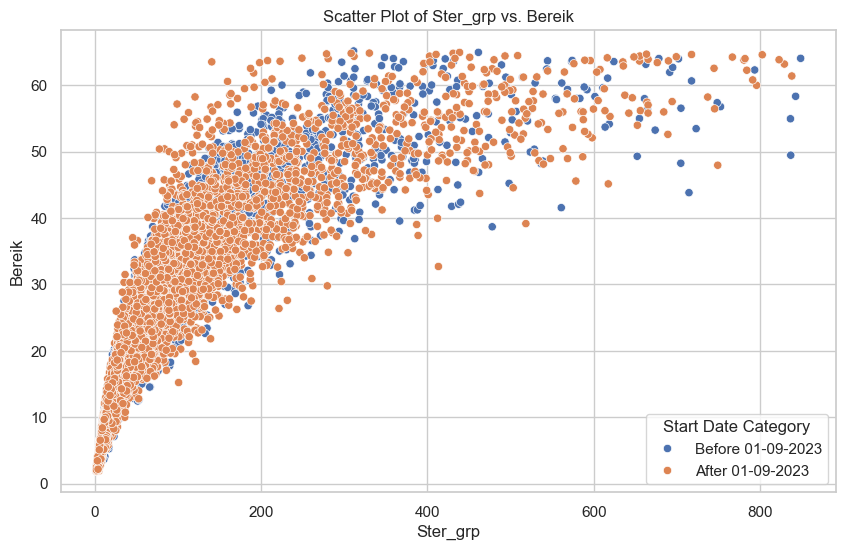

In [124]:
# Convert start_date to datetime format if it's not already
df['start_date'] = pd.to_datetime(df['start_date'], format='%d-%m-%Y')

# Create a new column to categorize the dates
df['date_category'] = df['start_date'].apply(lambda x: 'Before 01-09-2023' if x < pd.Timestamp('2023-09-01') else 'After 01-09-2023')

# Create the scatter plot
plt.figure(figsize=(10, 6))
scatter_plot = sns.scatterplot(data=df, x='ster_grp_total', y='ster_1+_total', hue='date_category')

# Customize the plot
plt.title('Scatter Plot of Ster_grp vs. Bereik')
plt.xlabel('Ster_grp')
plt.ylabel('Bereik')
plt.legend(title='Start Date Category')

# Show the plot
plt.show()

<Figure size 1200x800 with 0 Axes>

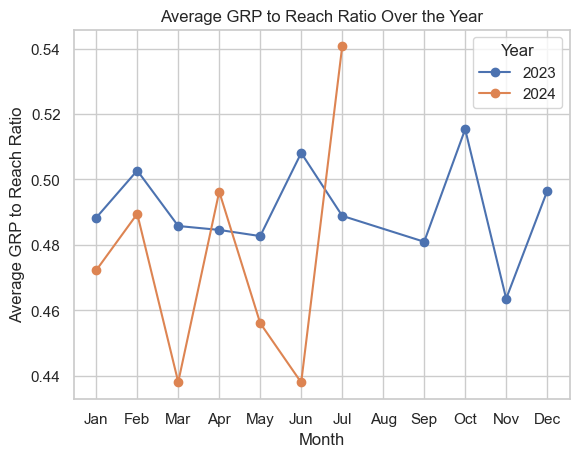

In [125]:
# Calculate GRP to reach ratio
df['grp_to_reach_ratio'] = df['ster_1+_total'] / df['ster_grp_total']

# Extract month and year from the date
df['year'] = df['start_date'].dt.year
df['month'] = df['start_date'].dt.month

# Group by year and month, then calculate mean GRP to reach ratio
monthly_avg_ratio = df.groupby(['year', 'month'])['grp_to_reach_ratio'].mean().reset_index()

# Create a pivot table for better visualization
pivot_monthly_avg_ratio = monthly_avg_ratio.pivot(index='month', columns='year', values='grp_to_reach_ratio')

# Plot the GRP to reach ratio over the months
plt.figure(figsize=(12, 8))
pivot_monthly_avg_ratio.plot(kind='line', marker='o')
plt.xlabel('Month')
plt.ylabel('Average GRP to Reach Ratio')
plt.title('Average GRP to Reach Ratio Over the Year')
plt.legend(title='Year')
plt.grid(True)
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

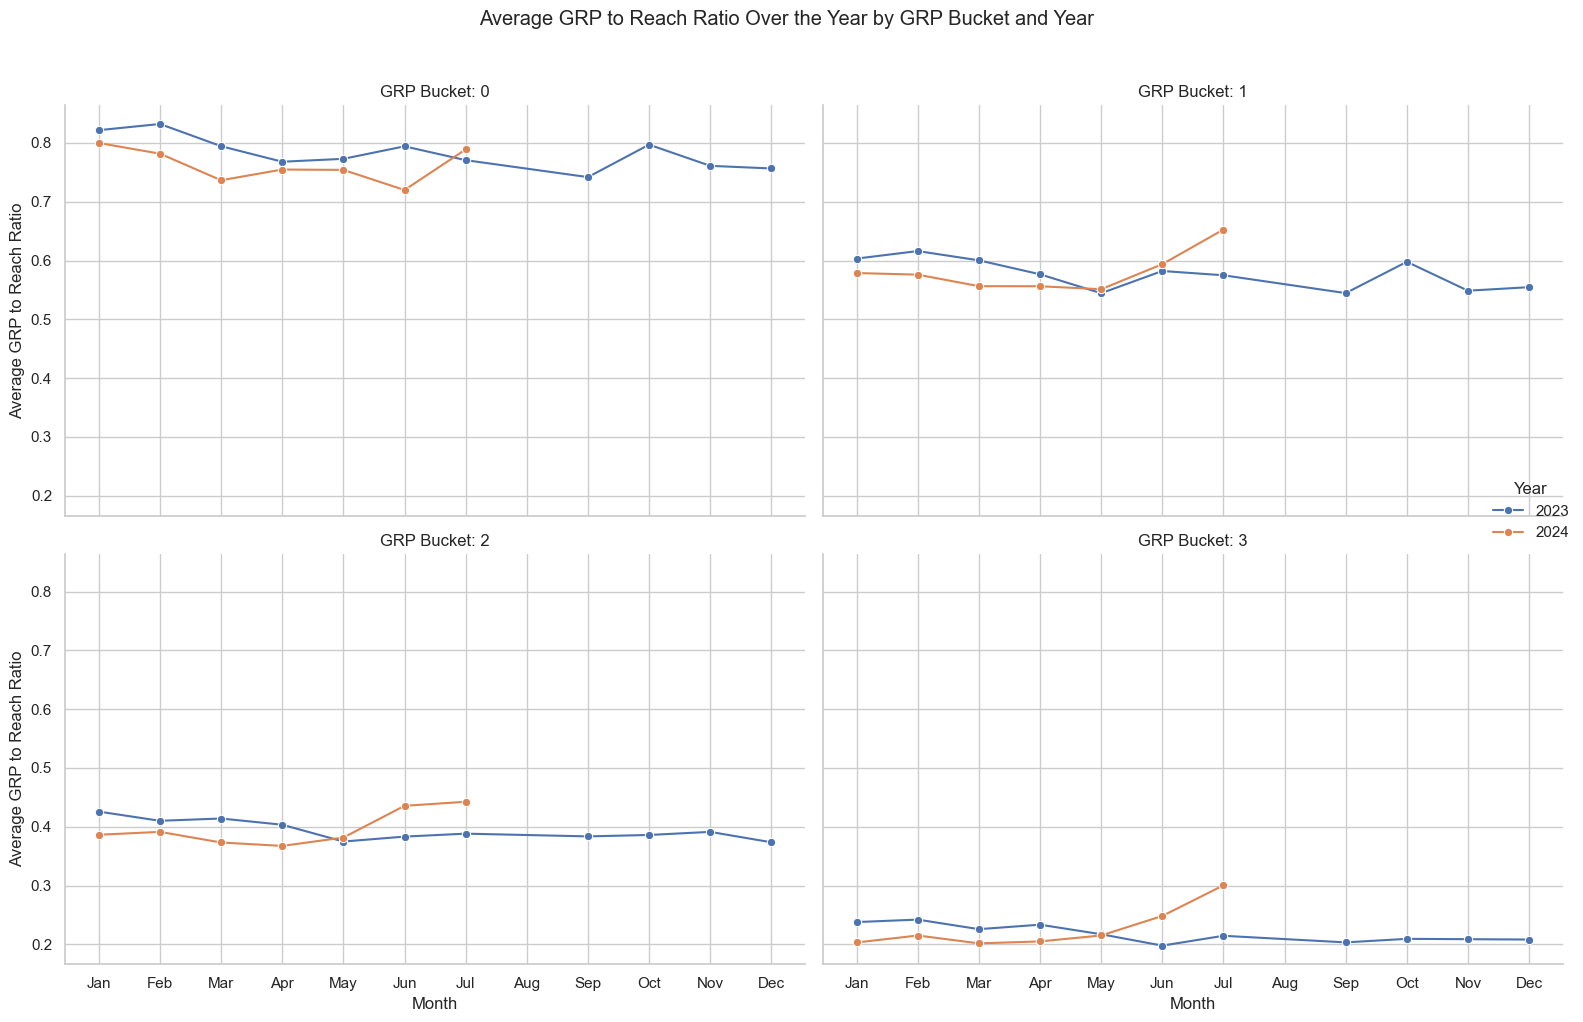

In [128]:
# Group by year, month, and GRP bucket, then calculate the mean GRP to reach ratio
grp_bucket_avg_ratio = df.groupby(['year', 'month', 'grp_bucket'])['grp_to_reach_ratio'].mean().reset_index()

# Plotting using Seaborn's FacetGrid
g = sns.FacetGrid(grp_bucket_avg_ratio, col='grp_bucket', hue='year', col_wrap=2, height=5, aspect=1.5)
g.map(sns.lineplot, 'month', 'grp_to_reach_ratio', marker='o')

# Set the axis labels and titles
g.set_axis_labels("Month", "Average GRP to Reach Ratio")
g.set_titles(col_template="GRP Bucket: {col_name}")
g.add_legend(title='Year')
g.set(xticks=range(1, 13), xticklabels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
g.fig.suptitle('Average GRP to Reach Ratio Over the Year by GRP Bucket and Year', y=1.02)

# Adjust the layout
plt.tight_layout()
plt.show()

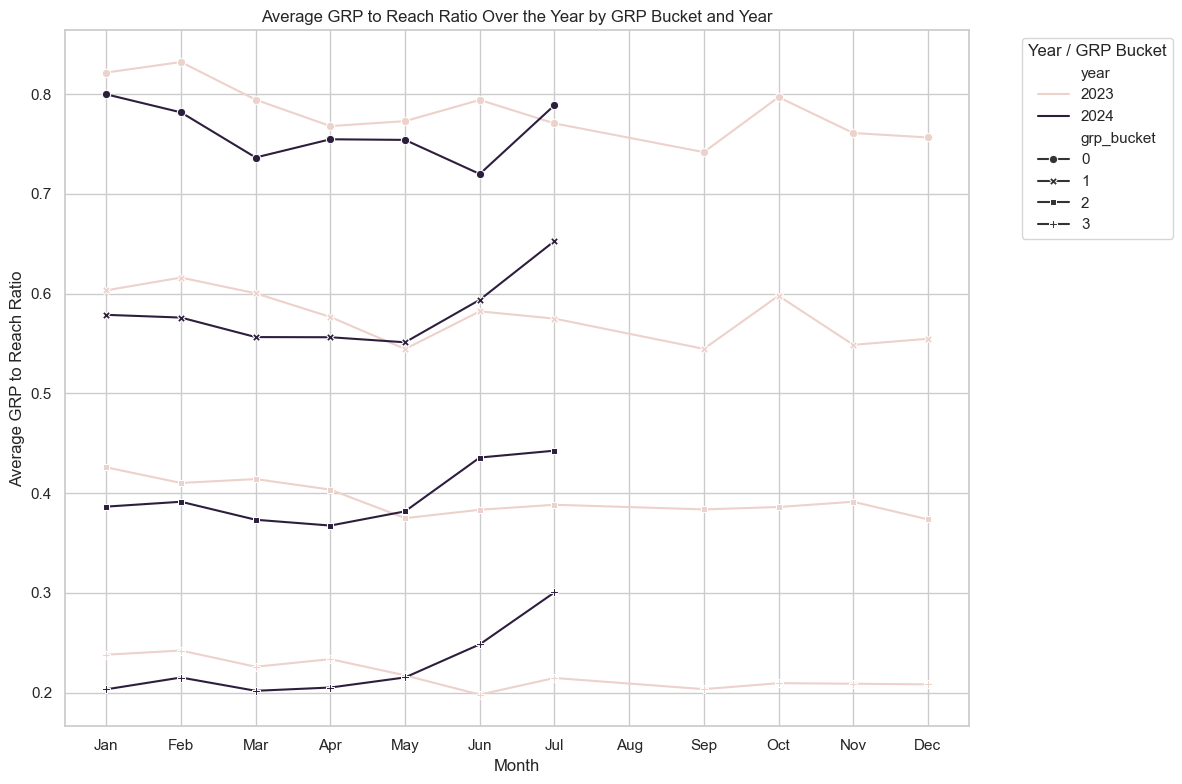

In [129]:
grp_bucket_avg_ratio = df.groupby(['year', 'month', 'grp_bucket'])['grp_to_reach_ratio'].mean().reset_index()

plt.figure(figsize=(12, 8))
sns.lineplot(data=grp_bucket_avg_ratio, x='month', y='grp_to_reach_ratio', hue='year', style='grp_bucket', markers=True, dashes=False)
plt.xlabel('Month')
plt.ylabel('Average GRP to Reach Ratio')
plt.title('Average GRP to Reach Ratio Over the Year by GRP Bucket and Year')
plt.legend(title='Year / GRP Bucket', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.tight_layout()
plt.show()